In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from deep_isochron.data import (
    resolve_device,
)
from deep_isochron.plotting import configure_rcparams
from deep_isochron.systems import FitzhughNagumo
from jaxtyping import Array, Float


jax.config.update("jax_enable_x64", True)
device = resolve_device(
    2
)  # the card the scheduler assigned; refuses to guess on a shared node
jax.config.update("jax_default_device", device)
configure_rcparams()

E1018 16:20:16.334114 2106609 platform_util.cc:279] Failed to create stream executor for device CUDA:3: CUDA error: : CUDA_ERROR_UNKNOWN: unknown error


## Initial long intergration for settling down

Corresponds to the Brute-force approach in section 5.1.1, Parker and Chua, Practical numerical algorithms for chaotic systems

In [2]:
ode = FitzhughNagumo()

In [125]:
ts = jnp.linspace(0, 10.0, 100)
u0 = jnp.asarray([3.0, 3.0])

sol_prev = ode.flow(ts, u0)

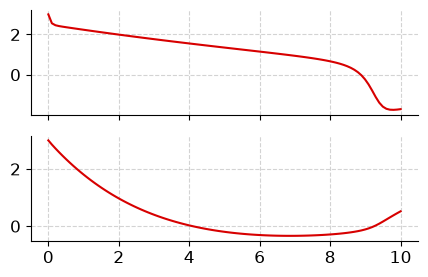

In [126]:
fig, axes = plt.subplots(2, 1, figsize=(5, 3), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(ts, sol_prev.ys[:, i])

## Confirm that the reached point is roughly on the limit cycle by setting up a section and computing the action of the one-sided Poincare map.

In [127]:
import diffrax as dfx
import optimistix as optx


u1 = sol_prev.ys[-1]
t1 = sol_prev.ts[-1]


class Hyperplane(eqx.Module):
    base_point: Float[Array, " dim"]
    normal: Float[Array, " dim"]

    @property
    def dim(self) -> int:
        return len(self.normal)

    def which_side(
        self, t, x: Float[Array, " dim"], args=None, **kwargs
    ) -> Float[Array, ""]:
        return jnp.dot(self.normal, x - self.base_point)


plane = Hyperplane(u1, ode.rhs(t1, u1))


def event_fn(t, y, args, **kwargs):
    return plane.which_side(t, y, args, **kwargs)


term = dfx.ODETerm(ode.rhs)
root_finder = optx.Newton(1e-5, 1e-5, optx.rms_norm)
controller = dfx.PIDController(atol=1e-6, rtol=1e-6)
solver = dfx.Tsit5()
sol = dfx.diffeqsolve(
    term,
    solver,
    t1,
    jnp.inf,
    None,
    u1,
    event=dfx.Event(event_fn, root_finder, direction=False),
    stepsize_controller=controller,
)

dfx.PIDController(atol=1e-6, rtol=1e-6)

t2, u2 = sol.ts[-1], sol.ys[-1]
sol2 = dfx.diffeqsolve(
    term,
    solver,
    t2,
    jnp.inf,
    None,
    u2,
    event=dfx.Event(event_fn, root_finder, direction=True),
    stepsize_controller=controller,
)

In [128]:
T0 = sol2.ts[0] - t1
print(T0)

11.22788533544037


In [ ]:
class NotConvergedError(Exception):
    """Raised when a numerical algorithm does not meet convergence expectations."""

    pass


eps = (
    1e-5  # Lenient since this is only an initial guess for the downstream optimization
)
if (err := jnp.linalg.norm(sol2.ys[0] - u1)) > eps:
    raise NotConvergedError
print(err)

4.131585716378928e-07


In [130]:
ts = jnp.linspace(0, T0, 100)
gamma0 = ode.flow(ts, sol2.ys[0])

In [131]:
gamma0.ys.shape

(100, 2)

## Shooting method, with least-squares optimization via Levenberg-Marquardt. 

Phase condition implemented analogously to Julia's bifurcation kit, by constraining the point to belong in a chosen hyperplane.

In [132]:
# Initial conditions for the shooting method
m = 10
u0_multishoot = ode.flow(jnp.linspace(0, T0, m, endpoint=False), sol2.ys[0]).ys

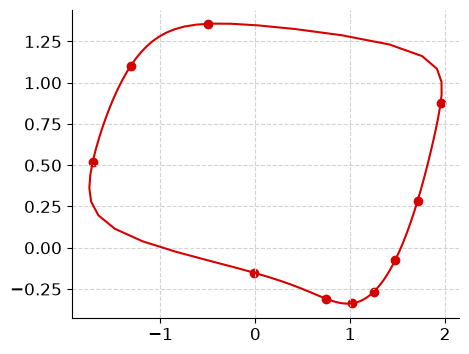

In [133]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(*gamma0.ys.T)
ax.scatter(*u0_multishoot.T)

In [134]:
def shoot(y, args):
    u0s, T = y
    n_segs = len(u0s)
    t1 = T / n_segs

    def _flow_segment(u0):
        sol = dfx.diffeqsolve(
            dfx.ODETerm(ode.rhs),
            dfx.Tsit5(),
            0,
            t1,
            None,
            u0,
            stepsize_controller=dfx.PIDController(atol=1e-6, rtol=1e-6),
            adjoint=dfx.ForwardMode(),
        )
        return sol.ys[0]

    u1 = eqx.filter_vmap(_flow_segment)(u0s)

    res_shoot = u1 - jnp.roll(u0s, -1, axis=0)

    plane = args
    res_phase = plane.which_side(0.0, u0s[0])
    return res_shoot, res_phase

In [135]:
shoot((u0_multishoot, T0), plane)

(Array([[-2.55245744e-06, -4.49399860e-08],
        [-1.07230225e-06,  7.26964762e-08],
        [-6.47685264e-07, -1.80632921e-07],
        [-1.06806426e-06, -7.77388233e-08],
        [-3.65426963e-07, -6.82856295e-08],
        [ 1.17621754e-06, -6.26518231e-08],
        [ 5.43956965e-07,  4.66242057e-08],
        [ 5.02707589e-07,  5.87268970e-08],
        [-6.96586909e-06,  8.77326221e-07],
        [ 4.66138966e-07,  5.01319941e-08]], dtype=float64),
 Array(-1.38369582e-17, dtype=float64))

In [136]:
import optimistix as optx


sol = optx.root_find(
    shoot,
    optx.LevenbergMarquardt(rtol=1e-6, atol=1e-8),
    y0=(u0_multishoot, T0),
    args=plane,
)

In [137]:
u0_multishoot

Array([[-1.7144251 ,  0.51975189],
       [-1.31333321,  1.10240425],
       [-0.49886867,  1.35747985],
       [ 1.95274121,  0.87587442],
       [ 1.71005509,  0.2846896 ],
       [ 1.4737435 , -0.07519553],
       [ 1.24699977, -0.26734029],
       [ 1.01876179, -0.33664882],
       [ 0.74679419, -0.3090825 ],
       [-0.01233617, -0.15143157]], dtype=float64)

In [138]:
T0

Array(11.22788534, dtype=float64)

In [139]:
sol.value

(Array([[-1.71442475,  0.51975175],
        [-1.31333589,  1.10240409],
        [-0.49887149,  1.35748029],
        [ 1.95274097,  0.8758757 ],
        [ 1.71005447,  0.28469038],
        [ 1.47374357, -0.07519509],
        [ 1.24700134, -0.26734012],
        [ 1.0187628 , -0.33664892],
        [ 0.74679546, -0.30908279],
        [-0.01233615, -0.15143186]], dtype=float64),
 Array(11.2278847, dtype=float64))

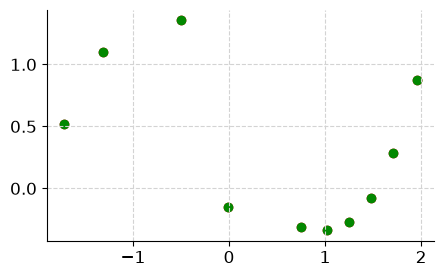

In [141]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.scatter(*u0_multishoot.T)
ax.scatter(*sol.value[0].T)